# Step 5 — KPI & Advanced Analytics

Pure Data Analytics — no Machine Learning and no Power BI.

### Objectives
- Calculate core student-performance KPIs
- Analyze study behavior, absences, failures and demographics
- Analyze family/support/lifestyle factors
- Compare performance groups
- Perform multi-variable cross-analysis
- Produce reusable analytical summary tables


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

df = pd.read_csv('../data/student_performance_cleaned.csv')

print('Dataset shape:', df.shape)
df.head()

Dataset shape: (395, 35)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance_category,pass
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Fail,Fail
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Fail,Fail
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Average,Pass
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Good,Pass
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Average,Pass


## 1. Core Student Performance KPIs

In [2]:
total_students = len(df)
average_grade = df['G3'].mean()
median_grade = df['G3'].median()
highest_grade = df['G3'].max()
lowest_grade = df['G3'].min()
std_grade = df['G3'].std()
pass_rate = (df['G3'] >= 10).mean() * 100
fail_rate = (df['G3'] < 10).mean() * 100
average_absences = df['absences'].mean()

kpis = pd.DataFrame({
    'KPI': ['Total Students','Average Final Grade','Median Final Grade','Highest Grade','Lowest Grade','Grade Std. Dev.','Pass Rate (%)','Fail Rate (%)','Average Absences'],
    'Value': [total_students, average_grade, median_grade, highest_grade, lowest_grade, std_grade, pass_rate, fail_rate, average_absences]
})

display(kpis)

,KPI,Value
0,Total Students,395.00
1,Average Final Grade,10.42
2,Median Final Grade,11.00
3,Highest Grade,20.00
4,Lowest Grade,0.00
5,Grade Std. Dev.,4.58
6,Pass Rate (%),67.09
7,Fail Rate (%),32.91
8,Average Absences,5.71


## 2. Performance Category Analysis

In [3]:
performance_summary = (
    df.groupby('performance_category')['G3']
      .agg(Student_Count='count', Average_Grade='mean', Median_Grade='median')
      .reset_index()
)

performance_summary['Percentage'] = (
    performance_summary['Student_Count'] / total_students * 100
).round(2)

order = ['Fail', 'Average', 'Good', 'Excellent']
performance_summary['performance_category'] = pd.Categorical(
    performance_summary['performance_category'], categories=order, ordered=True
)
performance_summary = performance_summary.sort_values('performance_category')
display(performance_summary.round(2))

,performance_category,Student_Count,Average_Grade,Median_Grade,Percentage
2,Fail,130,5.38,7.00,32.91
0,Average,165,11.22,11.00,41.77
3,Good,76,14.86,15.00,19.24
1,Excellent,24,18.04,18.00,6.08


## 3. Study Time Analysis

In [4]:
study_summary = (
    df.groupby('studytime')
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Median_Grade=('G3','median'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100),
          Average_Absences=('absences','mean')
      )
      .reset_index()
)

study_summary['Study_Time_Label'] = study_summary['studytime'].map({
    1: '<2 hours', 2: '2–5 hours', 3: '5–10 hours', 4: '>10 hours'
})

display(study_summary.round(2))

,studytime,Students,Average_Grade,Median_Grade,Pass_Rate,Average_Absences,Study_Time_Label
0,1,105,10.05,10.00,64.76,5.76,<2 hours
1,2,198,10.17,11.00,64.65,6.28,2–5 hours
2,3,65,11.40,12.00,75.38,4.54,5–10 hours
3,4,27,11.26,12.00,74.07,4.15,>10 hours


## 4. Absence Group Analysis

In [5]:
df['absence_group'] = pd.cut(
    df['absences'],
    bins=[-1, 5, 10, 20, np.inf],
    labels=['Low (0–5)', 'Moderate (6–10)', 'High (11–20)', 'Very High (21+)']
)

absence_summary = (
    df.groupby('absence_group', observed=False)
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Median_Grade=('G3','median'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100),
          Average_Absences=('absences','mean')
      )
      .reset_index()
)

display(absence_summary.round(2))

,absence_group,Students,Average_Grade,Median_Grade,Pass_Rate,Average_Absences
0,Low (0–5),249,10.17,11.00,68.27,1.58
1,Moderate (6–10),80,11.40,11.00,73.75,7.60
2,High (11–20),51,10.12,10.00,56.86,14.65
3,Very High (21+),15,10.27,9.00,46.67,33.73


## 5. Previous Failure Analysis

In [6]:
failure_summary = (
    df.groupby('failures')
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Median_Grade=('G3','median'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
      .reset_index()
)

display(failure_summary.round(2))

,failures,Students,Average_Grade,Median_Grade,Pass_Rate
0,0,312,11.25,11.00,75.00
1,1,50,8.12,9.00,48.00
2,2,17,6.24,8.00,17.65
3,3,16,5.69,7.00,25.00


## 6. Demographic Analysis

In [7]:
def group_performance(data, column):
    return (
        data.groupby(column, dropna=False)['G3']
            .agg(Students='count', Average_Grade='mean', Median_Grade='median',
                 Pass_Rate=lambda x: (x >= 10).mean() * 100)
            .reset_index()
    )

gender_summary = group_performance(df, 'sex')
school_summary = group_performance(df, 'school')
address_summary = group_performance(df, 'address')
famsize_summary = group_performance(df, 'famsize')

print('Gender')
display(gender_summary.round(2))

print('School')
display(school_summary.round(2))

print('Address')
display(address_summary.round(2))

print('Family Size')
display(famsize_summary.round(2))

Gender


,sex,Students,Average_Grade,Median_Grade,Pass_Rate
0,F,208,9.97,10.00,63.94
1,M,187,10.91,11.00,70.59


School


,school,Students,Average_Grade,Median_Grade,Pass_Rate
0,GP,349,10.49,11.00,67.62
1,MS,46,9.85,10.00,63.04


Address


,address,Students,Average_Grade,Median_Grade,Pass_Rate
0,R,88,9.51,10.00,62.50
1,U,307,10.67,11.00,68.40


Family Size


,famsize,Students,Average_Grade,Median_Grade,Pass_Rate
0,GT3,281,10.18,11.00,65.84
1,LE3,114,11.00,11.00,70.18


## 7. Parental Education Analysis

In [8]:
df['parent_education'] = df['Medu'] + df['Fedu']

parent_summary = (
    df.groupby('parent_education')
      .agg(
          Students=('G3','count'),
          Average_Grade=('G3','mean'),
          Median_Grade=('G3','median'),
          Pass_Rate=('G3', lambda x: (x >= 10).mean() * 100)
      )
      .reset_index()
)

display(parent_summary.round(2))

,parent_education,Students,Average_Grade,Median_Grade,Pass_Rate
0,1,2,12.50,12.50,50.00
1,2,39,8.64,10.00,58.97
2,3,43,9.26,10.00,60.47
3,4,72,9.60,10.00,59.72
4,5,47,10.40,11.00,68.09
5,6,64,11.30,11.00,75.00
6,7,58,10.95,11.00,67.24
7,8,70,11.66,12.00,75.71


## 8. Support System Analysis

In [9]:
support_columns = ['schoolsup', 'famsup', 'paid']

support_results = []

for col in support_columns:
    temp = (
        df.groupby(col)['G3']
          .agg(Students='count', Average_Grade='mean', Median_Grade='median',
               Pass_Rate=lambda x: (x >= 10).mean() * 100)
          .reset_index()
    )
    temp.insert(0, 'Factor', col)
    temp = temp.rename(columns={col: 'Group'})
    support_results.append(temp)

support_summary = pd.concat(support_results, ignore_index=True)
display(support_summary.round(2))

,Factor,Group,Students,Average_Grade,Median_Grade,Pass_Rate
0,schoolsup,no,344,10.56,11.00,68.90
1,schoolsup,yes,51,9.43,10.00,54.90
2,famsup,no,153,10.64,11.00,70.59
3,famsup,yes,242,10.27,11.00,64.88
4,paid,no,214,9.99,11.00,63.08
5,paid,yes,181,10.92,11.00,71.82


## 9. Lifestyle Analysis

In [10]:
lifestyle_columns = ['internet', 'activities', 'romantic', 'freetime', 'goout', 'Walc', 'Dalc']

for col in lifestyle_columns:
    print(f'\n--- {col} ---')
    if df[col].dtype == 'object':
        result = group_performance(df, col)
    else:
        result = group_performance(df, col)
    display(result.round(2))


--- internet ---


,internet,Students,Average_Grade,Median_Grade,Pass_Rate
0,no,66,9.41,10.00,60.61
1,yes,329,10.62,11.00,68.39



--- activities ---


,activities,Students,Average_Grade,Median_Grade,Pass_Rate
0,no,194,10.34,11.00,66.49
1,yes,201,10.49,11.00,67.66



--- romantic ---


...

,goout,Students,Average_Grade,Median_Grade,Pass_Rate
0,1,23,9.87,11.00,73.91
1,2,103,11.19,12.00,76.70
2,3,130,10.96,11.00,71.54
3,4,86,9.65,10.00,55.81
4,5,53,9.04,10.00,52.83



--- Walc ---


,Walc,Students,Average_Grade,Median_Grade,Pass_Rate
0,1,151,10.74,11.00,66.89
1,2,85,10.08,11.00,70.59
2,3,80,10.72,10.00,68.75
3,4,51,9.69,10.00,60.78
4,5,28,10.14,10.00,64.29



--- Dalc ---


,Dalc,Students,Average_Grade,Median_Grade,Pass_Rate
0,1,276,10.73,11.00,69.93
1,2,75,9.25,10.00,58.67
2,3,26,10.50,10.00,65.38
3,4,9,9.89,9.00,44.44
4,5,9,10.67,11.00,77.78


## 10. Performance Profile Analysis

In [11]:
profile_columns = ['studytime', 'absences', 'failures', 'Medu', 'Fedu', 'G1', 'G2', 'G3']

profile_summary = (
    df.groupby('performance_category')[profile_columns]
      .mean(numeric_only=True)
      .reindex(['Fail','Average','Good','Excellent'])
)

display(profile_summary.round(2))

,studytime,absences,failures,Medu,Fedu,G1,G2,G3
performance_category,,,,,,,,
Fail,1.95,6.76,0.69,2.57,2.35,7.76,6.82,5.38
Average,2.00,6.05,0.23,2.61,2.49,10.95,11.04,11.22
Good,2.20,3.37,0.04,3.17,2.71,14.24,14.50,14.86
Excellent,2.25,5.08,0.04,3.33,3.04,17.12,17.54,18.04


## 11. Cross Analysis — Study Time × Previous Failures

In [12]:
study_failure = (
    df.pivot_table(
        index='studytime',
        columns='failures',
        values='G3',
        aggfunc='mean'
    )
)

print('Average Final Grade by Study Time × Previous Failures')
display(study_failure.round(2))

Average Final Grade by Study Time × Previous Failures


failures,0,1,2,3
studytime,,,,
1,11.59,8.12,2.83,5.56
2,10.82,8.15,7.29,5.86
3,12.02,7.71,9.50,NaN
4,11.31,10.00,NaN,NaN


## 12. Cross Analysis — Absence Group × Study Time

In [13]:
absence_study = (
    df.pivot_table(
        index='absence_group',
        columns='studytime',
        values='G3',
        aggfunc='mean',
        observed=False
    )
)

print('Average Final Grade by Absence Group × Study Time')
display(absence_study.round(2))

Average Final Grade by Absence Group × Study Time


studytime,1,2,3,4
absence_group,,,,
Low (0–5),9.49,10.20,11.09,10.00
Moderate (6–10),12.17,10.03,12.07,12.55
High (11–20),8.71,10.21,13.67,16.00
Very High (21+),10.75,10.11,10.00,NaN


## 13. Cross Analysis — Parent Education × Study Time

In [14]:
parent_study = (
    df.pivot_table(
        index='parent_education',
        columns='studytime',
        values='G3',
        aggfunc='mean'
    )
)

print('Average Final Grade by Parent Education × Study Time')
display(parent_study.round(2))

Average Final Grade by Parent Education × Study Time


studytime,1,2,3,4
parent_education,,,,
1,NaN,12.50,NaN,NaN
2,7.21,8.71,11.00,11.00
3,8.75,9.50,9.80,NaN
4,10.07,8.66,11.67,10.15
5,10.12,10.14,10.25,16.00
6,10.92,11.06,12.27,11.80
7,9.89,11.28,10.79,11.33
8,12.22,10.82,12.75,12.50


## 14. Correlation Ranking with Final Grade

In [15]:
numeric_columns = df.select_dtypes(include=np.number).columns

correlation_with_g3 = (
    df[numeric_columns]
      .corr()['G3']
      .drop('G3')
      .sort_values(key=lambda x: x.abs(), ascending=False)
)

correlation_table = correlation_with_g3.reset_index()
correlation_table.columns = ['Variable', 'Correlation_with_G3']

display(correlation_table.round(3))

,Variable,Correlation_with_G3
0,G2,0.91
1,G1,0.80
2,failures,-0.36
3,Medu,0.22
4,parent_education,0.20
5,age,-0.16
6,Fedu,0.15
7,goout,-0.13
8,traveltime,-0.12
9,studytime,0.10


## 15. Visualization — KPI Overview

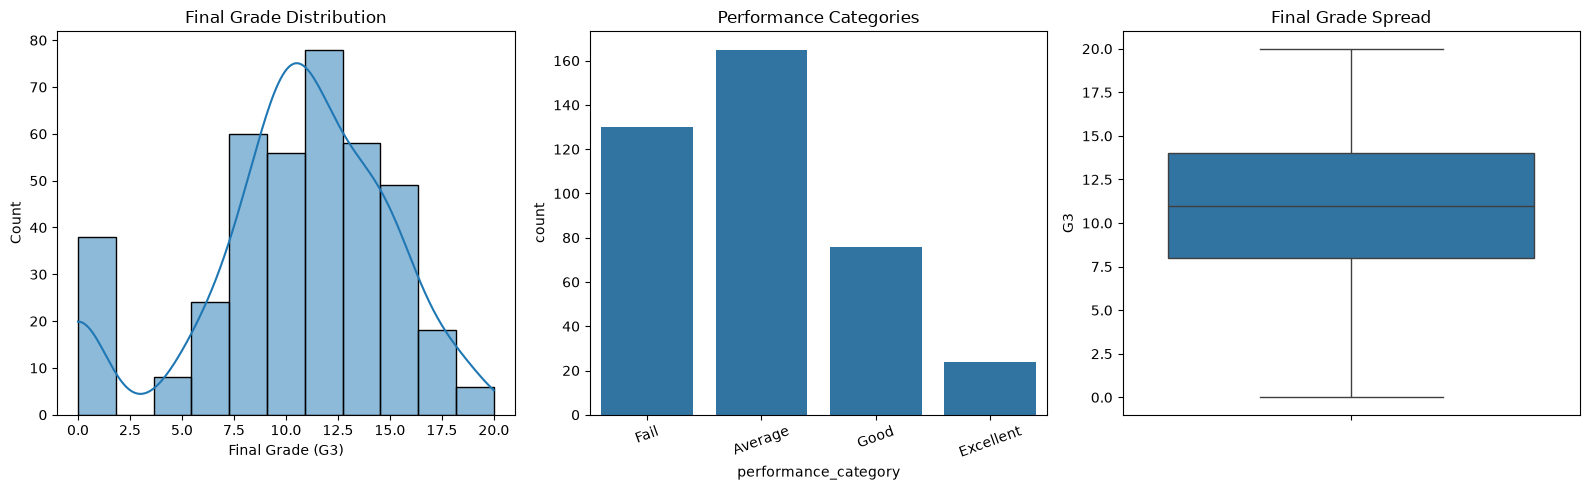

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(df['G3'], bins=11, kde=True, ax=axes[0])
axes[0].set_title('Final Grade Distribution')
axes[0].set_xlabel('Final Grade (G3)')

sns.countplot(data=df, x='performance_category', order=['Fail','Average','Good','Excellent'], ax=axes[1])
axes[1].set_title('Performance Categories')
axes[1].tick_params(axis='x', rotation=20)

sns.boxplot(data=df, y='G3', ax=axes[2])
axes[2].set_title('Final Grade Spread')

plt.tight_layout()
plt.show()

## 16. Visualization — Advanced Comparisons

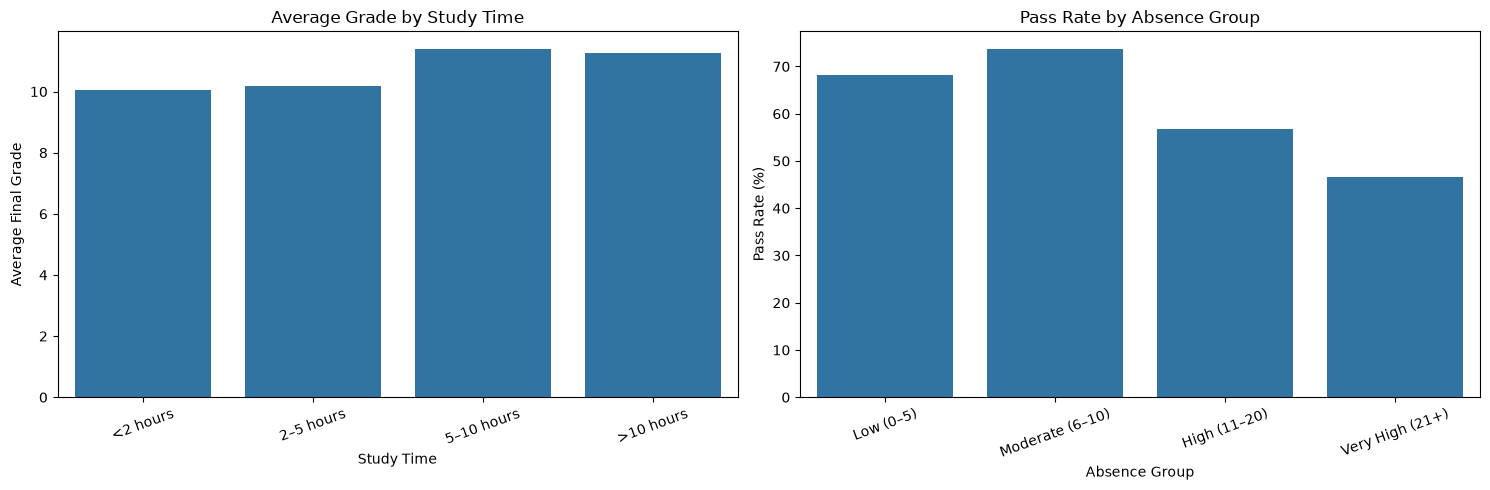

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=study_summary, x='Study_Time_Label', y='Average_Grade', ax=axes[0])
axes[0].set_title('Average Grade by Study Time')
axes[0].set_xlabel('Study Time')
axes[0].set_ylabel('Average Final Grade')
axes[0].tick_params(axis='x', rotation=20)

sns.barplot(data=absence_summary, x='absence_group', y='Pass_Rate', ax=axes[1])
axes[1].set_title('Pass Rate by Absence Group')
axes[1].set_xlabel('Absence Group')
axes[1].set_ylabel('Pass Rate (%)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

import os

## 17. Export Analytical Results

Save the main analytical tables so they can be reused in reports or later visualizations.

In [20]:
import os
os.makedirs('../analysis_results', exist_ok=True)

kpis.to_csv('../analysis_results/kpis.csv', index=False)
performance_summary.to_csv('../analysis_results/performance_summary.csv', index=False)
study_summary.to_csv('../analysis_results/study_summary.csv', index=False)
absence_summary.to_csv('../analysis_results/absence_summary.csv', index=False)
failure_summary.to_csv('../analysis_results/failure_summary.csv', index=False)
gender_summary.to_csv('../analysis_results/gender_summary.csv', index=False)
school_summary.to_csv('../analysis_results/school_summary.csv', index=False)
parent_summary.to_csv('../analysis_results/parent_education_summary.csv', index=False)
support_summary.to_csv('../analysis_results/support_summary.csv', index=False)
correlation_table.to_csv('../analysis_results/correlation_with_g3.csv', index=False)

print('Analytical results exported successfully to analysis_results/')

Analytical results exported successfully to analysis_results/


# Step 5 Complete

At this point the project contains:

- Core performance KPIs
- Performance segmentation
- Study-time analysis
- Absence analysis
- Previous-failure analysis
- Demographic comparisons
- Parent education analysis
- Support-system analysis
- Lifestyle analysis
- Multi-variable cross-analysis
- Correlation ranking
- Analytical visualizations
- Exported summary tables

**Important:** These analyses describe associations and group differences. They do not establish that any factor causes a change in student performance.
